In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yaml
import sys

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.append(os.path.join(PROJECT_ROOT, "src"))
from plotting_utils import save_fig

with open(os.path.join(PROJECT_ROOT, "config", "config.yaml")) as f:
    config = yaml.safe_load(f)

SEED = config["seed"]
RAW_DIR = os.path.join(PROJECT_ROOT, config["paths"]["raw_dir"])

raw_path = os.path.join(RAW_DIR, config["raw_files"]["uganda"])
df = pd.read_csv(raw_path)
print("Shape:", df.shape)

Shape: (14325, 24)


In [2]:
df.head()

,category,age,homeDistrict,homeCounty,homeSubCounty,homeParish,occupation,workDistrict,workCounty,workSubCounty,workParish,relationshipStatus,spouseOccupation,polygamy,otherChildren,numStillBorn,numMissCarry,education,evaluation_date,dueDate,hospital,followup_status,Total Score,Anxiety
0,0,33,Kampala,KCCA,Central Division,Old Kampala,informal business owner,Kampala,KCCA,Central Division,Old Kampala,Cohabiting,informal business owner,Yes,2,0,1,A-level,31/01/2022,28/06/2022,Mengo Kisenyi HCIV,NaN,13,5
1,0,36,Kampala,KCCA,Central Division,Kamwokya Ii,Unemployed,NaN,NaN,NaN,NaN,Traditional Marriage,formal business owner,No,1,0,1,Degree/Diploma,01/02/2022,08/03/2022,KCCA hospital,NaN,12,2
2,0,31,Kampala,KCCA,Nakawa Division,Mutungo,Unemployed,NaN,NaN,NaN,NaN,Cohabiting,informal business owner,Yes,1,1,1,O-level,01/02/2022,14/06/2022,KCCA hospital,pending,14,3
3,0,26,Kampala,KCCA,Nakawa Division,Bugolobi,informal business owner,Kampala,KCCA,Central Division,Bukesa,Formal Union,informal business owner,No,2,1,0,O-level,01/02/2022,01/02/2022,KCCA HCIII - Bugolobi,pending,13,4
4,0,14,Kampala,KCCA,Central Division,Industrial Area,formal business owner,Kampala,KCCA,Nakawa Division,Bugolobi,Formal Union,formal employee,No,1,1,1,O-level,01/02/2022,01/02/2022,KCCA HCIII - Bugolobi,pending,11,5


In [3]:
df.dtypes

category              int64
age                     str
homeDistrict            str
homeCounty              str
homeSubCounty           str
homeParish              str
occupation              str
workDistrict            str
workCounty              str
workSubCounty           str
workParish              str
relationshipStatus      str
spouseOccupation        str
polygamy                str
otherChildren         int64
numStillBorn          int64
numMissCarry          int64
education               str
evaluation_date         str
dueDate                 str
hospital                str
followup_status         str
Total Score           int64
Anxiety               int64
dtype: object

In [4]:
df["age_numeric"] = pd.to_numeric(df["age"], errors="coerce")
n_bad = df["age_numeric"].isna().sum()
print(f"Non-numeric age values: {n_bad}")
print(df.loc[df["age_numeric"].isna(), "age"].unique())
print(df["age_numeric"].describe())

Non-numeric age values: 7
<StringArray>
['#VALUE!']
Length: 1, dtype: str
count    14318.000000
mean        27.126624
std          5.336019
min         10.000000
25%         23.000000
50%         26.000000
75%         30.000000
max         54.000000
Name: age_numeric, dtype: float64


In [5]:
missing = df.isna().sum().sort_values(ascending=False)
print(missing)

followup_status       9818
workCounty            9166
workDistrict          9166
workParish            9166
workSubCounty         2515
age_numeric              7
category                 0
age                      0
homeDistrict             0
homeParish               0
occupation               0
homeCounty               0
homeSubCounty            0
polygamy                 0
otherChildren            0
relationshipStatus       0
spouseOccupation         0
numMissCarry             0
numStillBorn             0
education                0
evaluation_date          0
hospital                 0
dueDate                  0
Total Score              0
Anxiety                  0
dtype: int64


In [6]:
print("category unique values:", df["category"].unique())
print()
print("followup_status value counts:")
print(df["followup_status"].value_counts(dropna=False))
# category is constant (all 0) and followup_status is >65% missing with only one
# real value ("pending") when present — both are candidates to drop in preprocessing (04).

category unique values: [0]

followup_status value counts:
followup_status
NaN        9818
pending    4507
Name: count, dtype: int64


In [7]:
print(df["Total Score"].describe())
print()
print(df["Anxiety"].describe())
print()
print(df["Anxiety"].value_counts().sort_index())

count    14325.000000
mean        10.050052
std          3.983745
min          0.000000
25%          8.000000
50%         10.000000
75%         12.000000
max         29.000000
Name: Total Score, dtype: float64

count    14325.000000
mean         3.642653
std          1.611571
min          0.000000
25%          3.000000
50%          3.000000
75%          5.000000
max          9.000000
Name: Anxiety, dtype: float64

Anxiety
0     473
1     654
2    1970
3    4206
4    2770
5    2196
6    1574
7     403
8      67
9      12
Name: count, dtype: int64


Saved figure: C:\maternal-mental-health-risk\reports\figures\uganda\outcome_distributions.png


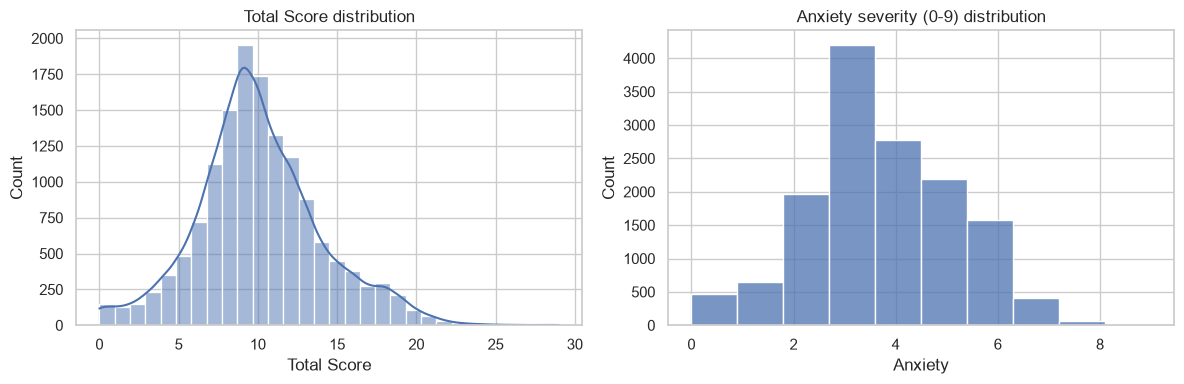

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Total Score"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Total Score distribution")
sns.histplot(df["Anxiety"], bins=10, kde=False, ax=axes[1])
axes[1].set_title("Anxiety severity (0-9) distribution")
plt.tight_layout()
save_fig(fig, "outcome_distributions.png", PROJECT_ROOT, dataset="uganda")
plt.show()

In [9]:
numeric_cols = ["age_numeric", "otherChildren", "numStillBorn", "numMissCarry"]
df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
age_numeric,14318.0,27.126624,5.336019,10.0,23.0,26.0,30.0,54.0
otherChildren,14325.0,1.611449,1.351236,0.0,0.0,2.0,3.0,5.0
numStillBorn,14325.0,0.880140,0.324810,0.0,1.0,1.0,1.0,1.0
numMissCarry,14325.0,0.687609,0.463484,0.0,0.0,1.0,1.0,1.0


Saved figure: C:\maternal-mental-health-risk\reports\figures\uganda\numeric_distributions.png


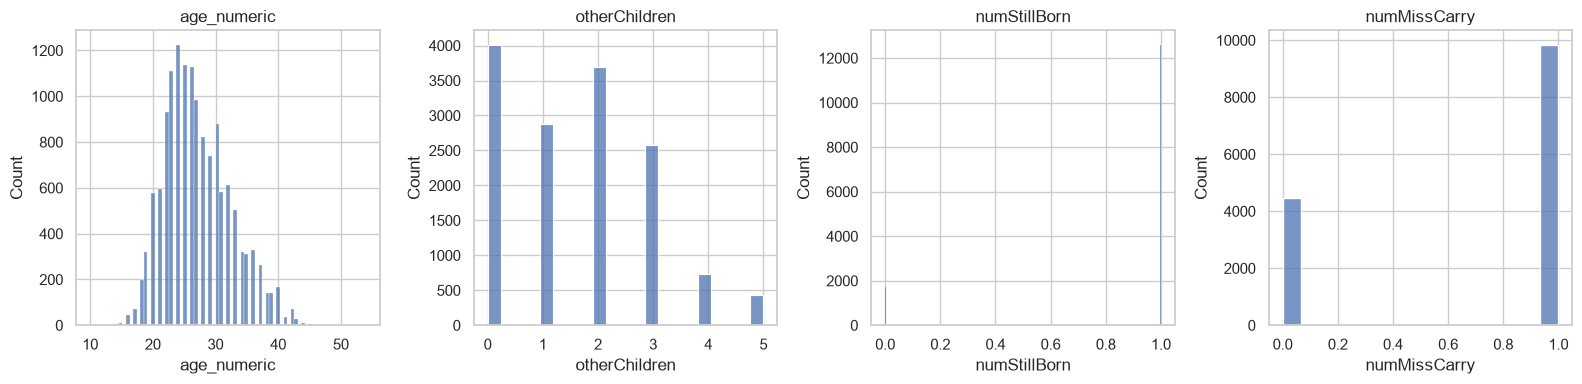

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, numeric_cols):
    sns.histplot(df[col].dropna(), kde=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()
save_fig(fig, "numeric_distributions.png", PROJECT_ROOT, dataset="uganda")
plt.show()

In [11]:
sdoh_cols = ["occupation", "relationshipStatus", "spouseOccupation", "polygamy", "education", "hospital"]

for col in sdoh_cols:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False))
    print()

--- occupation ---
occupation
Unemployed                 9166
informal business owner    2281
formal business owner      1314
informal employee           846
formal employee             718
Name: count, dtype: int64

--- relationshipStatus ---
relationshipStatus
Cohabiting              7210
Traditional Marriage    4289
Single                  1252
Formal Union            1025
Separated                494
Widowed                   55
Name: count, dtype: int64

--- spouseOccupation ---
spouseOccupation
informal business owner    3685
informal employee          3575
formal employee            2574
Unemployed                 2323
formal business owner      2168
Name: count, dtype: int64

--- polygamy ---
polygamy
No     9491
Yes    4834
Name: count, dtype: int64

--- education ---
education
O-level                8478
P5 or Higher           2420
A-level                1679
Lower Primary/ None    1157
Degree/Diploma          591
Name: count, dtype: int64

--- hospital ---
hospital
Komamboga

Saved figure: C:\maternal-mental-health-risk\reports\figures\uganda\sdoh_distributions.png


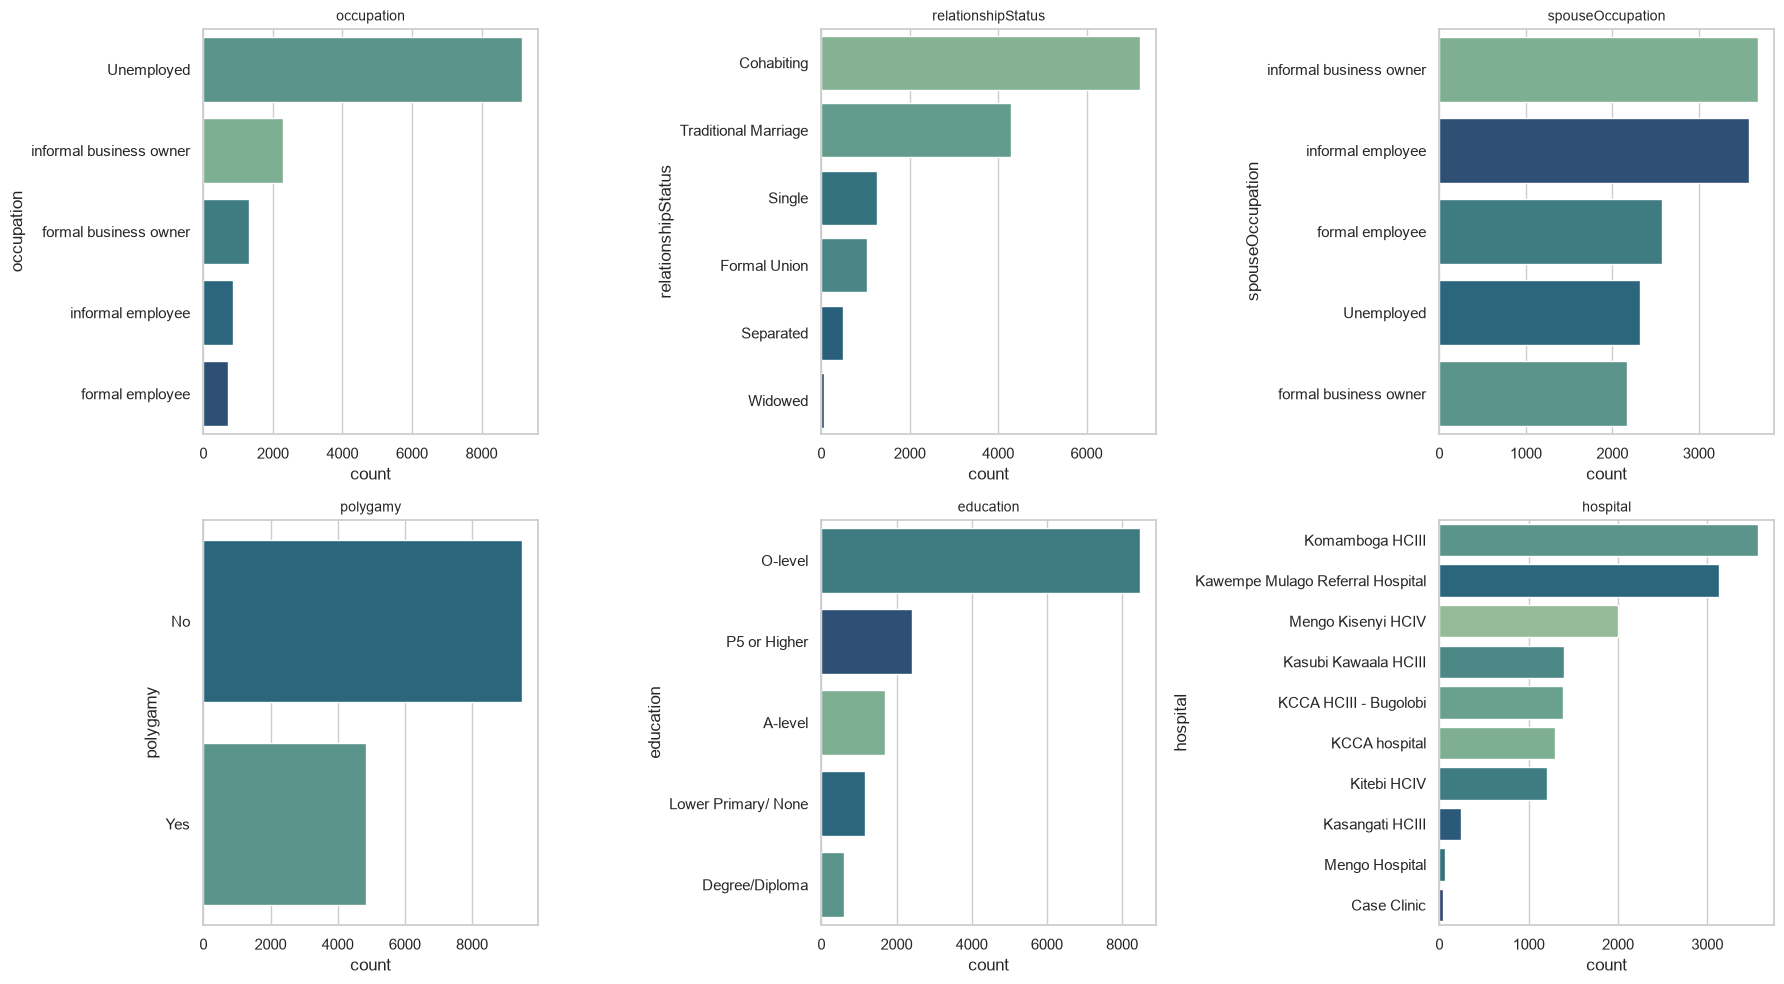

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, col in zip(axes.flat, sdoh_cols):
    order = df[col].value_counts().index[:10]  # top 10 in case of high cardinality (e.g. hospital)
    sns.countplot(data=df, y=col, order=order, hue=col, palette="crest", legend=False, ax=ax)
    ax.set_title(col, fontsize=10)
plt.tight_layout()
save_fig(fig, "sdoh_distributions.png", PROJECT_ROOT, dataset="uganda")
plt.show()

homeDistrict
Kampala       9382
Wakiso        4550
Kalangala       96
Mukono          88
Luwero          39
Mpigi           37
Kiboga          28
Mityana         19
Lyantonde       15
Masaka          12
Kayunga         11
Rakai            9
Ssembabule       8
Kyankwanzi       6
Mubende          4
Name: count, dtype: int64
Saved figure: C:\maternal-mental-health-risk\reports\figures\uganda\top_home_districts.png


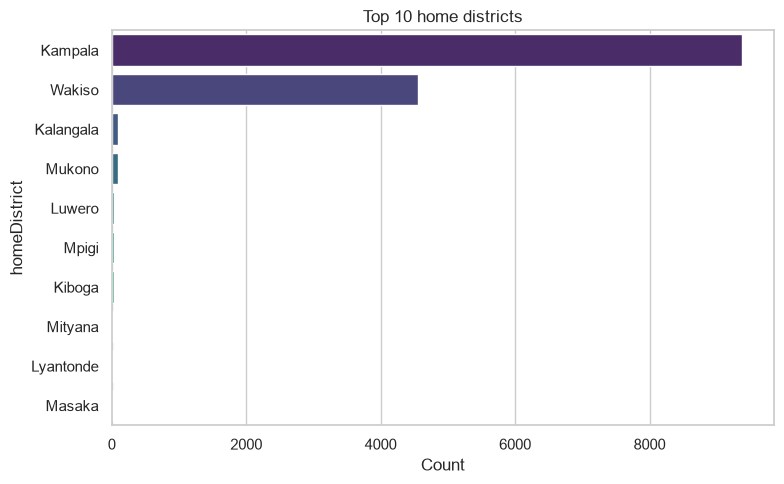

In [13]:
print(df["homeDistrict"].value_counts(dropna=False).head(15))

fig, ax = plt.subplots(figsize=(8, 5))
top_districts = df["homeDistrict"].value_counts().head(10)
sns.barplot(x=top_districts.values, y=top_districts.index, hue=top_districts.index,
            palette="viridis", legend=False, ax=ax)
ax.set_title("Top 10 home districts")
ax.set_xlabel("Count")
plt.tight_layout()
save_fig(fig, "top_home_districts.png", PROJECT_ROOT, dataset="uganda")
plt.show()

Saved figure: C:\maternal-mental-health-risk\reports\figures\uganda\sdoh_vs_anxiety.png


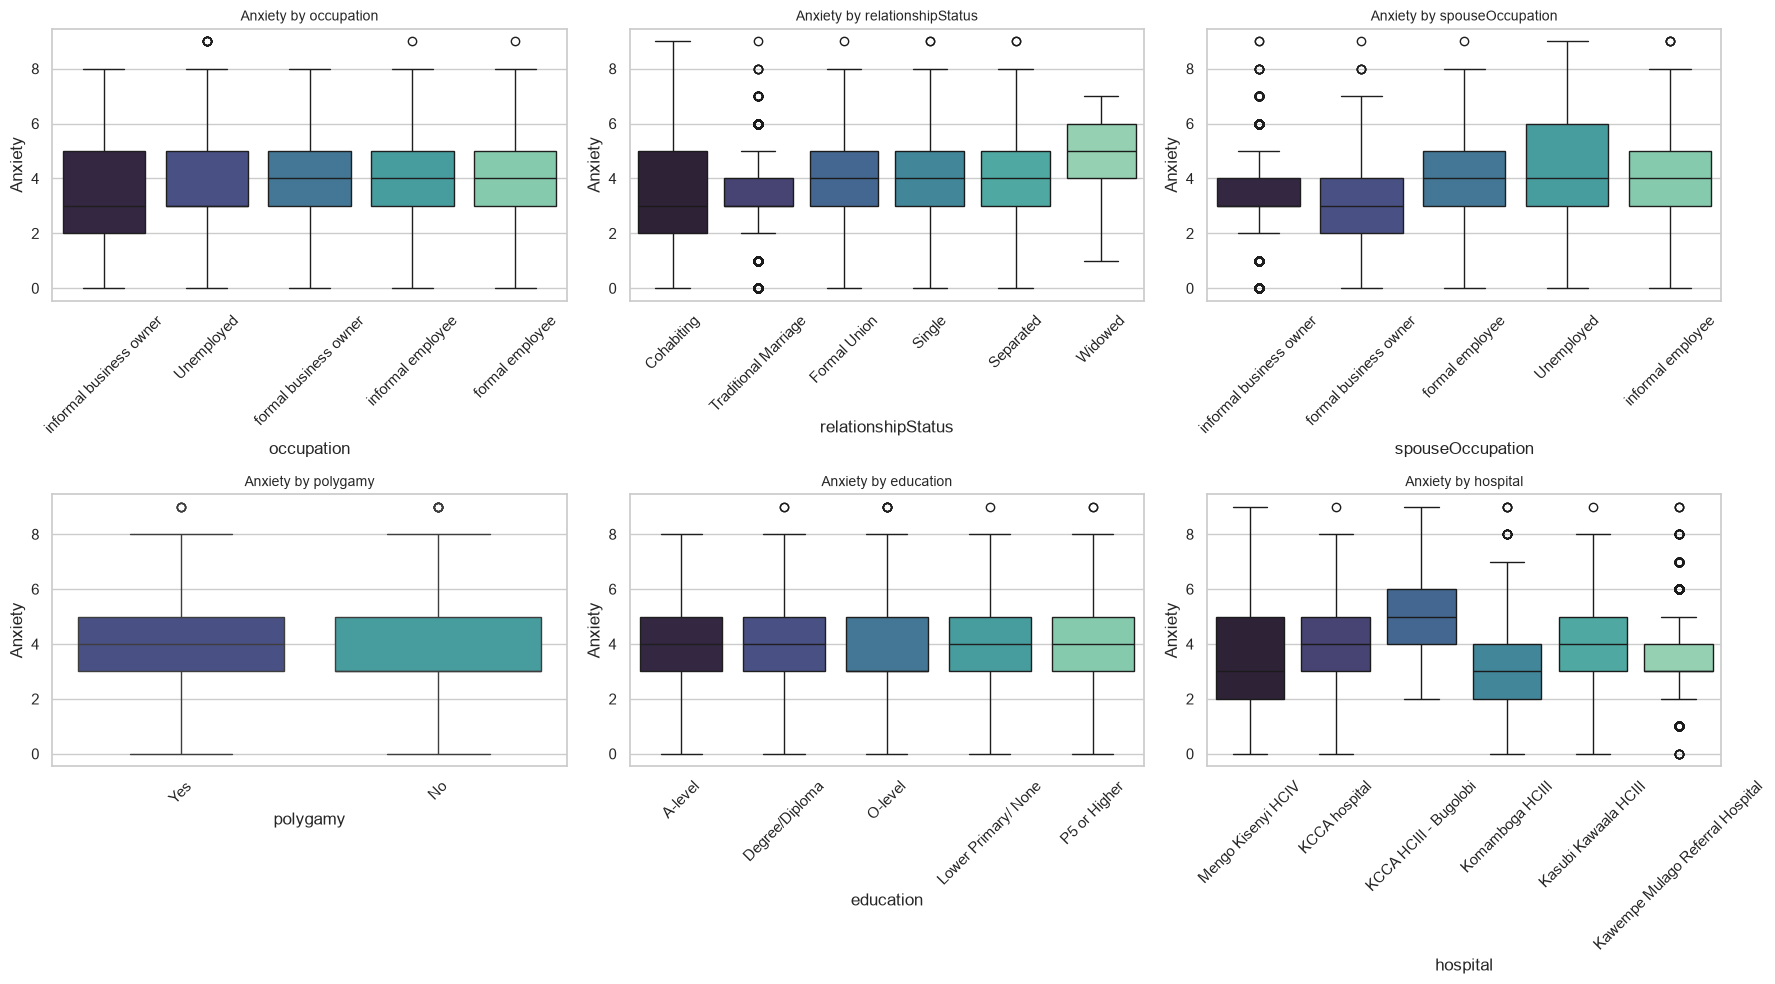

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, col in zip(axes.flat, sdoh_cols):
    top_levels = df[col].value_counts().index[:6]
    subset = df[df[col].isin(top_levels)]
    sns.boxplot(data=subset, x=col, y="Anxiety", hue=col, palette="mako", legend=False, ax=ax)
    ax.set_title(f"Anxiety by {col}", fontsize=10)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
save_fig(fig, "sdoh_vs_anxiety.png", PROJECT_ROOT, dataset="uganda")
plt.show()

Saved figure: C:\maternal-mental-health-risk\reports\figures\uganda\numeric_correlation_heatmap.png


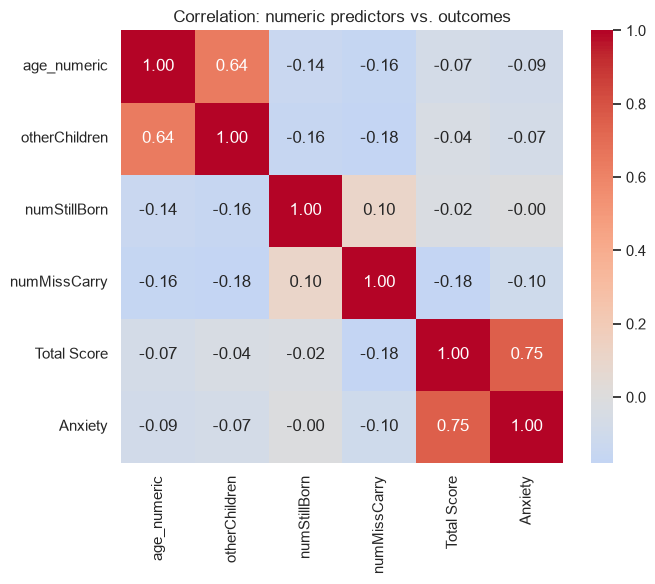

In [15]:
corr_cols = numeric_cols + ["Total Score", "Anxiety"]
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation: numeric predictors vs. outcomes")
plt.tight_layout()
save_fig(fig, "numeric_correlation_heatmap.png", PROJECT_ROOT, dataset="uganda")
plt.show()